# GoEmotions project proposition

**Question.** On short Reddit comments, how do document representation and classifier depth affect multilabel emotion recognition?

GoEmotions contains 43,410 train, 5,426 development, and 5,427 test comments with 27 emotions plus `neutral`; 16.36% of training examples have multiple labels. Training support ranges from 77 (`grief`) to 14,219 (`neutral`). Therefore this is a strongly imbalanced **multilabel**, not multiclass, task. The primary metric is macro-F1 (every emotion has equal weight); micro-F1 is reported as context. The official test set stays untouched until the final evaluation.

This notebook covers the assignment checklist with a full $3\times3$ comparison:

| Requirement | Choices |
|---|---|
| Representations | BPE token indicators; BPE token-count bag of words; BPE TF-IDF |
| Architectures | one-vs-rest log-linear; one-hidden-layer MLP; two-hidden-layer MLP |
| Comparison | identical shuffled folds, macro/micro-F1, mean and fold variation |
| Bayesian analysis | correlated $t$ posterior for the best two systems; ROPE $=\pm0.005$ macro-F1 |

**Tutorial alignment.** As in `tutorial.ipynb`, a Hugging Face BPE tokenizer uses Metaspace pre-tokenization, `vocab_size=1000`, and `min_frequency=2`; it is trained once on the official training texts and saved for reproducibility. Indicators and counts are the tutorial encoders; TF-IDF is the required extra representation. The tutorial's multiclass softmax models cannot represent multiple simultaneous emotions, so their GoEmotions adaptations use 28 sigmoid decisions and binary cross-entropy while retaining the same linear/hidden-layer distinction.

In [1]:
# Cell 1 — Configure reproducibility, locate the archive, and load all official splits.
from pathlib import Path
import csv, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import baycomp
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Metaspace
from tokenizers.trainers import BpeTrainer
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, make_scorer
from sklearn.model_selection import KFold, cross_validate
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MultiLabelBinarizer

SEED = 0
CV_SEEDS = [0]            # Tutorial default; use [0, 3, 5] for repeated CV if time permits
QUICK_RUN = False         # True = 6,000-row smoke test; False = reportable full experiment
N_SPLITS = 3 if QUICK_RUN else 5
MAX_ROWS = 6_000 if QUICK_RUN else None
BPE_VOCAB_SIZE = 1_000
BPE_MIN_FREQUENCY = 2
ROPE = 0.005              # tutorial convention: half a macro-F1 percentage point

def locate_data():
    for base in (Path.cwd(), *Path.cwd().parents):
        candidate = base / 'archive' / 'data'
        if (candidate / 'train.tsv').exists():
            return candidate
    raise FileNotFoundError('Could not find archive/data from the current working directory.')

DATA_DIR = locate_data()
LABELS = (DATA_DIR / 'emotions.txt').read_text(encoding='utf-8').splitlines()
mlb = MultiLabelBinarizer(classes=np.arange(len(LABELS))).fit([[]])

def read_split(name):
    frame = pd.read_csv(DATA_DIR / f'{name}.tsv', sep='\t', header=None,
                        names=['text', 'label_ids', 'id'], quoting=csv.QUOTE_NONE)
    frame['label_ids'] = frame['label_ids'].map(lambda s: [int(i) for i in s.split(',')])
    return frame, mlb.transform(frame['label_ids'])

splits = {name: read_split(name) for name in ('train', 'dev', 'test')}
train, Y_train = splits['train']
rng = np.random.default_rng(SEED)
cv_idx = (np.sort(rng.choice(len(train), MAX_ROWS, replace=False))
          if MAX_ROWS and MAX_ROWS < len(train) else np.arange(len(train)))
X_cv, Y_cv = train.iloc[cv_idx]['text'].reset_index(drop=True), Y_train[cv_idx]

# Tutorial recipe: train BPE on training text only and persist it.
RESULTS_DIR = DATA_DIR.parents[1] / 'goemotions_results'
RESULTS_DIR.mkdir(exist_ok=True)
BPE_PATH = RESULTS_DIR / f'bpe_vs{BPE_VOCAB_SIZE}_mf{BPE_MIN_FREQUENCY}.json'
tokenizer = Tokenizer(BPE(unk_token='[UNK]'))
tokenizer.pre_tokenizer = Metaspace()
trainer = BpeTrainer(vocab_size=BPE_VOCAB_SIZE, min_frequency=BPE_MIN_FREQUENCY,
                     special_tokens=['[UNK]'])
tokenizer.train_from_iterator(train['text'], trainer=trainer)
tokenizer.save(str(BPE_PATH))
BPE_VOCAB = tokenizer.get_vocab()

def bpe_analyzer(text):
    return tokenizer.encode(text).tokens

print(f'Data: {DATA_DIR} | mode: {"QUICK" if QUICK_RUN else "FULL"} | CV rows: {len(X_cv):,}')
print(f'BPE vocabulary: {len(BPE_VOCAB):,} tokens | saved to: {BPE_PATH}')
display(pd.DataFrame({
    'setting': ['CV mode', 'folds', 'BPE vocabulary', 'BPE min frequency', 'ROPE'],
    'value': [('quick' if QUICK_RUN else 'full'), N_SPLITS, BPE_VOCAB_SIZE, BPE_MIN_FREQUENCY, ROPE],
}))

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\piter\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Data: C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\archive\data | mode: FULL | CV rows: 43,410
BPE vocabulary: 1,000 tokens | saved to: C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\goemotions_results\bpe_vs1000_mf2.json


,setting,value
0,CV mode,full
1,folds,5
2,BPE vocabulary,1000
3,BPE min frequency,2
4,ROPE,0.005


,split,examples,mean_labels,multilabel_%
0,train,43410,1.18,16.36
1,dev,5426,1.18,16.18
2,test,5427,1.17,15.42


,label,train_count
0,neutral,14219
1,admiration,4130
2,approval,2939
3,gratitude,2662
4,annoyance,2470
5,amusement,2328
6,curiosity,2191
7,love,2086
8,disapproval,2022
9,optimism,1581


Sample text: My favourite food is anything I didn't have to cook myself.
BPE tokens: ['▁My', '▁fa', 'v', 'our', 'ite', '▁f', 'ood', '▁is', '▁any', 'thing', '▁I', '▁did', "n't", '▁have', '▁to', '▁c', 'ook', '▁my', 'self', '.']


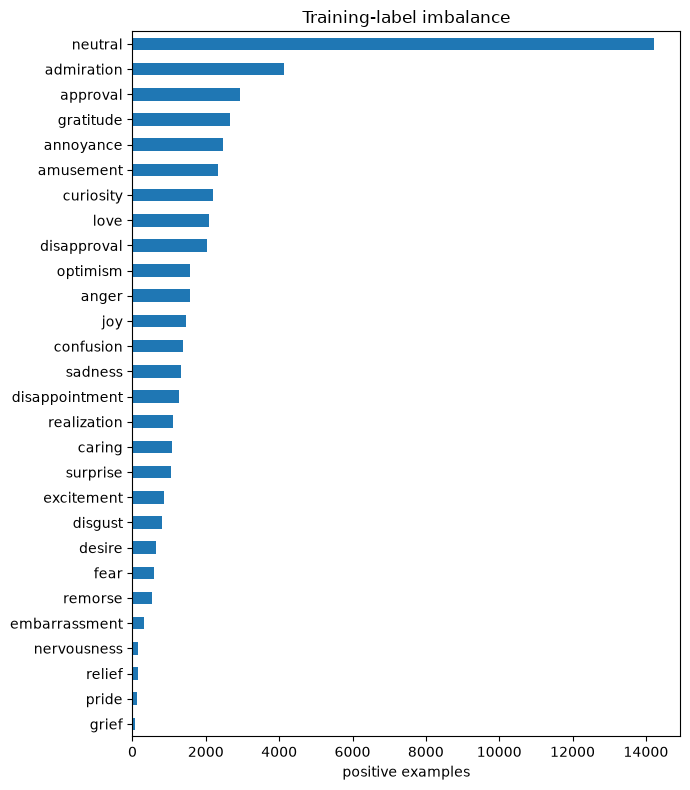

In [2]:
# Cell 2 — Verify split sizes, label cardinality, imbalance, and multilabel frequency.
overview = []
for name, (frame, Y) in splits.items():
    per_item = Y.sum(axis=1)
    overview.append({'split': name, 'examples': len(frame),
                     'mean_labels': per_item.mean(), 'multilabel_%': 100 * (per_item > 1).mean()})
display(pd.DataFrame(overview).round(2))

label_counts = pd.DataFrame({'label': LABELS, 'train_count': Y_train.sum(axis=0)})
display(label_counts.sort_values('train_count', ascending=False).reset_index(drop=True))
ax = label_counts.sort_values('train_count').plot.barh(
    x='label', y='train_count', figsize=(7, 8), legend=False, title='Training-label imbalance')
ax.set(xlabel='positive examples', ylabel=''); plt.tight_layout()
sample = train.iloc[0]['text']
print('Sample text:', sample)
print('BPE tokens:', bpe_analyzer(sample))

## Experiment design

All systems use the same saved BPE vocabulary, exactly separating **tokenization** from **document encoding** as the tutorial does. Binary indicators test BPE-token presence, counts implement the tutorial bag of words, and sublinear TF-IDF is the additional representation. IDF values and every classifier are estimated only on each fold's training partition.

The log-linear model uses one logistic decision per label. The one-hidden-layer MLP follows the tutorial's 128-unit ReLU design, batch size 64, learning rate $10^{-4}$, weight decay $10^{-4}$, and 10 epochs. Scikit-learn's multilabel MLP uses sigmoid outputs and binary cross-entropy; its `alpha` is the tutorial's weight decay, but it does not expose dropout. A two-hidden-layer `(128, 64)` MLP is the required architectural extension.

The tutorial's shuffled five-fold procedure is reproduced with identical paired folds for every system. Random K-fold is not iterative multilabel stratification, but even the rarest training label has 77 positives, making an empty full-data fold unlikely. The official test set remains untouched until selection is complete.

In [3]:
# Cell 3 — Construct exactly three representations × three architectures (nine pipelines).
bpe_args = dict(analyzer=bpe_analyzer, vocabulary=BPE_VOCAB, lowercase=False)
representations = {
    'BPE indicator': CountVectorizer(binary=True, **bpe_args),
    'BPE count': CountVectorizer(binary=False, **bpe_args),
    'BPE tfidf': TfidfVectorizer(sublinear_tf=True, norm='l2', **bpe_args),
}
architectures = {
    'log-linear': OneVsRestClassifier(
        LogisticRegression(solver='liblinear', max_iter=100, random_state=SEED), n_jobs=1),
    'MLP-1': MLPClassifier(hidden_layer_sizes=(128,), activation='relu', solver='adam',
                           batch_size=64, learning_rate_init=1e-4, alpha=1e-4,
                           max_iter=10, early_stopping=False, random_state=SEED),
    'MLP-2': MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam',
                           batch_size=64, learning_rate_init=1e-4, alpha=1e-4,
                           max_iter=10, early_stopping=False, random_state=SEED),
}
systems = {f'{rep} + {arch}': make_pipeline(clone(vectorizer), clone(model))
           for rep, vectorizer in representations.items()
           for arch, model in architectures.items()}
design_table = pd.DataFrame([(rep, arch, f'{rep} + {arch}')
                             for rep in representations for arch in architectures],
                            columns=['representation', 'architecture', 'system'])
display(design_table)

,representation,architecture,system
0,BPE indicator,log-linear,BPE indicator + log-linear
1,BPE indicator,MLP-1,BPE indicator + MLP-1
2,BPE indicator,MLP-2,BPE indicator + MLP-2
3,BPE count,log-linear,BPE count + log-linear
4,BPE count,MLP-1,BPE count + MLP-1
5,BPE count,MLP-2,BPE count + MLP-2
6,BPE tfidf,log-linear,BPE tfidf + log-linear
7,BPE tfidf,MLP-1,BPE tfidf + MLP-1
8,BPE tfidf,MLP-2,BPE tfidf + MLP-2


BPE indicator + log-linear  finished in 1.1 min


C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


... (31 outputs left out)

C:\Users\piter\Desktop\UvA written works\Summaries\Artificial Intelligence Mast\Natural Language Processing 1\Projects\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


BPE tfidf + MLP-2           finished in 2.1 min


,system,macro_f1,macro_sd,micro_f1,mean_fit_s
0,BPE indicator + log-linear,0.2715,0.0101,0.4058,12.5981
1,BPE count + log-linear,0.2597,0.0097,0.3939,20.1056
2,BPE tfidf + log-linear,0.1897,0.0046,0.3584,7.1485
3,BPE indicator + MLP-2,0.1397,0.0045,0.3476,22.6973
4,BPE count + MLP-2,0.1349,0.0039,0.3387,24.2934
5,BPE indicator + MLP-1,0.1229,0.0025,0.3015,21.3470
6,BPE count + MLP-1,0.1213,0.0038,0.2941,19.3770
7,BPE tfidf + MLP-2,0.0719,0.0043,0.2381,24.4144
8,BPE tfidf + MLP-1,0.0350,0.0018,0.1132,21.5631


architecture,log-linear,MLP-1,MLP-2
representation,,,
BPE indicator,0.2715,0.1229,0.1397
BPE count,0.2597,0.1213,0.1349
BPE tfidf,0.1897,0.0350,0.0719


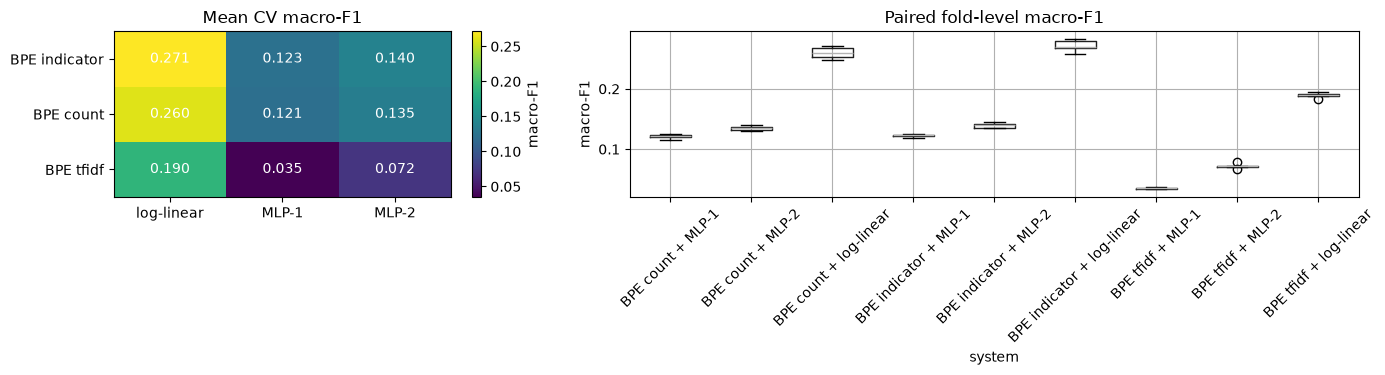

In [4]:
# Cell 4 — Run paired cross-validation and rank systems by the primary metric, macro-F1.
scoring = {
    'macro_f1': make_scorer(f1_score, average='macro', zero_division=0),
    'micro_f1': make_scorer(f1_score, average='micro', zero_division=0),
}
rows = []
for system, pipeline in systems.items():
    start = time.time()
    for run, seed in enumerate(CV_SEEDS):
        cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
        result = cross_validate(pipeline, X_cv, Y_cv, cv=cv, scoring=scoring,
                                n_jobs=1, error_score='raise')
        for fold in range(N_SPLITS):
            rows.append({'system': system, 'run': run, 'seed': seed, 'fold': fold,
                         'macro_f1': result['test_macro_f1'][fold],
                         'micro_f1': result['test_micro_f1'][fold],
                         'fit_seconds': result['fit_time'][fold]})
    print(f'{system:27s} finished in {(time.time() - start) / 60:.1f} min')

scores = pd.DataFrame(rows)
summary = (scores.groupby('system', as_index=False)
           .agg(macro_f1=('macro_f1', 'mean'), macro_sd=('macro_f1', 'std'),
                micro_f1=('micro_f1', 'mean'), mean_fit_s=('fit_seconds', 'mean'))
           .sort_values('macro_f1', ascending=False).reset_index(drop=True))
display(summary.round(4))
score_matrix = (summary.assign(representation=summary.system.str.rsplit(' + ', n=1).str[0],
                               architecture=summary.system.str.rsplit(' + ', n=1).str[1])
                .pivot(index='representation', columns='architecture', values='macro_f1')
                .reindex(index=representations, columns=architectures))
display(score_matrix.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1.1, 1.9]})
im = axes[0].imshow(score_matrix, cmap='viridis', aspect='auto')
axes[0].set(xticks=range(len(score_matrix.columns)), xticklabels=score_matrix.columns,
            yticks=range(len(score_matrix.index)), yticklabels=score_matrix.index, title='Mean CV macro-F1')
for i in range(score_matrix.shape[0]):
    for j in range(score_matrix.shape[1]):
        axes[0].text(j, i, f'{score_matrix.iloc[i, j]:.3f}', ha='center', va='center', color='white')
fig.colorbar(im, ax=axes[0], label='macro-F1')
scores.boxplot(column='macro_f1', by='system', rot=45, ax=axes[1])
axes[1].set(title='Paired fold-level macro-F1', xlabel='system', ylabel='macro-F1')
plt.suptitle(''); plt.tight_layout()

## Bayesian practical comparison

The top two systems are compared on their paired fold scores with the tutorial's Bayesian correlated $t$ model. Its posterior accounts for overlap among cross-validation training sets. Following the tutorial, the ROPE $[-0.005, 0.005]$ says that an expected difference below half a macro-F1 percentage point is practically negligible. Report the probabilities of A winning, practical equivalence, and B winning rather than a binary significance claim.

A: BPE indicator + log-linear
B: BPE count + log-linear
P(A wins)=0.992 | P(ROPE)=0.007 | P(B wins)=0.000
posterior mean(B−A)=-0.0118; effect size=-7.02


,system A (higher CV rank),system B,P(A wins),P(practical tie),P(B wins),mean B − A,ROPE
0,BPE indicator + log-linear,BPE count + log-linear,0.9923,0.0075,0.0003,-0.0118,±0.005


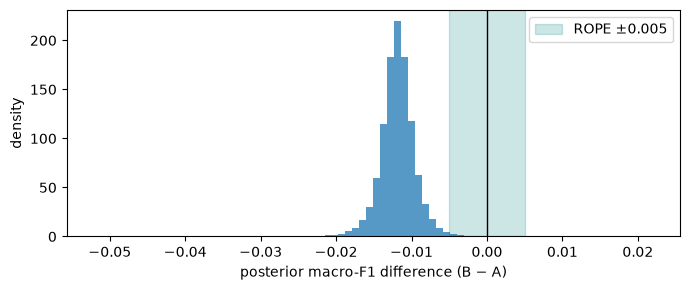

In [5]:
# Cell 5 — Estimate and visualise the posterior difference between the best two systems.
A, B = summary.loc[0, 'system'], summary.loc[1, 'system']
order = ['run', 'fold']
a = scores.loc[scores.system.eq(A)].sort_values(order)['macro_f1'].to_numpy()
b = scores.loc[scores.system.eq(B)].sort_values(order)['macro_f1'].to_numpy()
posterior = baycomp.CorrelatedTTest(a, b, rope=ROPE, runs=len(CV_SEEDS))  # B − A
p_A, p_rope, p_B = posterior.probs()
print(f'A: {A}\nB: {B}')
print(f'P(A wins)={p_A:.3f} | P(ROPE)={p_rope:.3f} | P(B wins)={p_B:.3f}')
print(f'posterior mean(B−A)={posterior.mean:.4f}; effect size={posterior.mean / np.sqrt(posterior.var):.2f}')
posterior_table = pd.DataFrame([{
    'system A (higher CV rank)': A, 'system B': B,
    'P(A wins)': p_A, 'P(practical tie)': p_rope, 'P(B wins)': p_B,
    'mean B − A': posterior.mean, 'ROPE': f'±{ROPE}',
}])
display(posterior_table.round(4))
samples = np.asarray(posterior.sample)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(samples, bins=80, density=True, alpha=.75)
ax.axvspan(-ROPE, ROPE, color='teal', alpha=.2, label=f'ROPE ±{ROPE}')
ax.axvline(0, color='black', lw=1); ax.set(xlabel='posterior macro-F1 difference (B − A)', ylabel='density')
ax.legend(); plt.tight_layout()

,BPE indicator + log-linear
macro_f1,0.286219
micro_f1,0.418729
subset_accuracy,0.275843


,label,support,predicted,f1
0,nervousness,23,6,0.000000
1,relief,11,1,0.000000
2,grief,6,0,0.000000
3,annoyance,320,23,0.046647
4,disappointment,151,12,0.073620
5,disapproval,267,40,0.078176
6,realization,145,18,0.122699
7,approval,351,39,0.128205
8,confusion,153,43,0.173469
9,sadness,156,48,0.176471


,text,gold,predicted
0,I’m really sorry about your situation :( Altho...,sadness,love
1,It's wonderful because it's awful. At not with.,admiration,∅
2,"Kings fan here, good luck to you guys! Will be...",excitement,admiration
3,You’re welcome,gratitude,∅
4,100%! Congrats on your job too!,gratitude,∅
5,I’m sorry to hear that friend :(. It’s for the...,remorse,"remorse, sadness"
6,"Girlfriend weak as well, that jump was pathetic.",sadness,∅
7,[NAME] has towed the line of the Dark Side. He...,"annoyance, disapproval",neutral
8,"It's great that you're a recovering addict, th...","admiration, curiosity",admiration
9,I never wanted to punch osap harder after seei...,disapproval,neutral


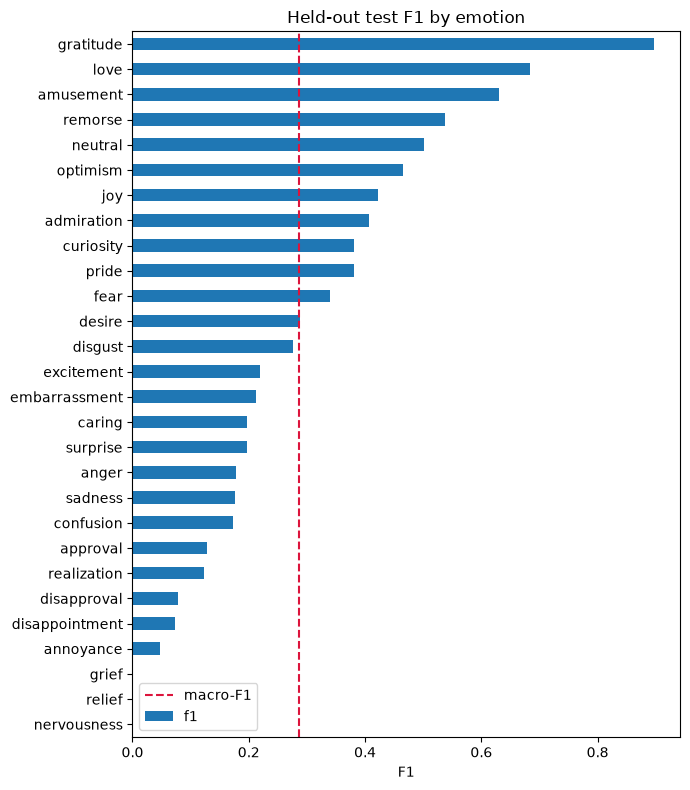

In [6]:
# Cell 6 — Refit the selected system on train+dev, evaluate test once, and expose errors.
best_name = A
dev, Y_dev = splits['dev']; test, Y_test = splits['test']
X_fit = pd.concat([train['text'], dev['text']], ignore_index=True)
Y_fit = np.vstack([Y_train, Y_dev])
if QUICK_RUN and MAX_ROWS is not None and MAX_ROWS < len(X_fit):
    final_idx = np.sort(rng.choice(len(X_fit), MAX_ROWS, replace=False))
    X_fit, Y_fit = X_fit.iloc[final_idx], Y_fit[final_idx] 

final_model = clone(systems[best_name]).fit(X_fit, Y_fit)
Y_pred = final_model.predict(test['text'])
final_metrics = pd.Series({
    'macro_f1': f1_score(Y_test, Y_pred, average='macro', zero_division=0),
    'micro_f1': f1_score(Y_test, Y_pred, average='micro', zero_division=0),
    'subset_accuracy': accuracy_score(Y_test, Y_pred),
}, name=best_name)
display(final_metrics.to_frame())

per_label = pd.DataFrame({'label': LABELS, 'support': Y_test.sum(axis=0),
                          'predicted': Y_pred.sum(axis=0),
                          'f1': f1_score(Y_test, Y_pred, average=None, zero_division=0)})
per_label_sorted = per_label.sort_values('f1').reset_index(drop=True)
display(per_label_sorted)
ax = per_label_sorted.plot.barh(x='label', y='f1', figsize=(7, 8), legend=False,
                                title='Held-out test F1 by emotion')
ax.set(xlabel='F1', ylabel=''); ax.axvline(final_metrics['macro_f1'], color='crimson',
       linestyle='--', label='macro-F1'); ax.legend(); plt.tight_layout()

def decode(row):
    return ', '.join(np.asarray(LABELS)[np.flatnonzero(row)]) or '∅'
mistakes = np.flatnonzero((Y_test != Y_pred).any(axis=1))[:10]
error_examples = pd.DataFrame({
    'text': test.iloc[mistakes]['text'].to_numpy(),
    'gold': [decode(Y_test[i]) for i in mistakes],
    'predicted': [decode(Y_pred[i]) for i in mistakes],
})
display(error_examples)

## How to finish and report

1. Use `QUICK_RUN=True` only to verify the notebook. For reportable numbers set it to `False`, restart the kernel, and run all cells.
2. Explain the tutorial transfer: BPE segmentation → indicators/counts → log-linear/MLP classifiers → paired cross-validation → Bayesian estimation. Explicitly justify sigmoid/BCE instead of softmax/NLL because GoEmotions is multilabel.
3. Report the ranked table, fold variation, the three posterior probabilities, and final test macro/micro-F1. Explain whether the runner-up is practically equivalent before preferring a more complex model.
4. Inspect the per-label table and error examples. Discuss rare-label recall, confusable emotions, multilabel misses, and whether TF-IDF or added depth helps. Subset accuracy is harsh because every label must match.
5. Limitations: the BPE tokenizer follows the tutorial by using all official training texts before CV (an unsupervised, transductive preprocessing choice); Reddit is not globally representative; labels are subjective; rare emotions make macro-F1 uncertain; random K-fold is not iterative multilabel stratification.

**Sources.** Demszky et al. (2020), *GoEmotions: A Dataset of Fine-Grained Emotions*; Benavoli et al. (2017), *Time for a Change: a Tutorial for Comparing Multiple Classifiers Through Bayesian Analysis*.

**AI-assistance record.** An AI coding assistant helped inspect the supplied files and draft this experimental notebook. The student remains responsible for running it, checking the results, understanding every design choice, and documenting any later AI-assisted changes.